# Prática II — Classificação de Dígitos de Hidrômetros com AlexNet, VGG16 e ResNet

Pipeline completo: aquisição → análise exploratória → construção do dataset de dígitos → treino de
`smallcnn`, `alexnet`, `vgg16_bn` e `resnet18` com protocolo idêntico → avaliação no conjunto de teste.

> As células marcadas com a tag `dataset-images` exibem imagens do dataset (licença CC BY-NC-ND 4.0) e têm a
> saída limpa antes do commit (`python tools/clear_image_outputs.py pratica_watermeters.ipynb`).

In [1]:
import os, re, ast, json, time, random, hashlib, shutil, collections, platform
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models
from torchvision.transforms import v2
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

SEED = 42
ROOT = Path('.').resolve()
# dados locais (cópia do Kaggle); se não existirem, a Parte 1 baixa pela API do Kaggle
DATA_DIR = Path(os.environ.get('WATERMETERS_DIR', ROOT.parent / 'vc-20262-p2' / 'data')).resolve()
DIGITS_DIR, CKPT_DIR, FIG_DIR, REPORT_DIR = ROOT / 'digits', ROOT / 'checkpoints', ROOT / 'figures', ROOT / 'reports'
for p in (DIGITS_DIR, CKPT_DIR, FIG_DIR, REPORT_DIR):
    p.mkdir(exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
FORCE_TRAIN = os.environ.get('FORCE_TRAIN', '1') == '1'  # 0 = reaproveita checkpoints/histórico existentes


def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
set_seed()

# paleta categórica (uma cor fixa por modelo em todas as figuras)
MODELS = ['smallcnn', 'alexnet', 'vgg16_bn', 'resnet18']
COLORS = dict(zip(MODELS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']))
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold'})

print('Python', platform.python_version(), '| torch', torch.__version__, '| torchvision', torchvision.__version__,
      '| OpenCV', cv2.__version__)
print('Dispositivo:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')
print('DATA_DIR:', DATA_DIR)

Python 3.12.10 | torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | OpenCV 5.0.0
Dispositivo: cuda NVIDIA GeForce RTX 5060 Ti
DATA_DIR: D:\programing\cesar\VC\vc-20262-p2\data


## Parte 1 — Aquisição dos dados

O dataset [Yandex.Toloka Water Meters](https://www.kaggle.com/datasets/tapakah68/yandextoloka-water-meters-dataset)
é baixado pela API do Kaggle (`kagglehub`, requer `~/.kaggle/kaggle.json`) quando não há cópia local em `DATA_DIR`.
Em seguida verificamos a integridade: arquivos esperados, correspondência entre pastas e `data.csv`, leitura de
todas as imagens, dimensões das máscaras e um hash SHA-256 do conjunto.

In [2]:
def acquire(data_dir):
    if (data_dir / 'data.csv').exists():
        print('Usando cópia local em', data_dir)
        return data_dir
    import kagglehub  # usa ~/.kaggle/kaggle.json
    path = Path(kagglehub.dataset_download('tapakah68/yandextoloka-water-meters-dataset'))
    found = next(path.rglob('data.csv')).parent
    print('Baixado do Kaggle em', found)
    return found


DATA_DIR = acquire(DATA_DIR)
for item in sorted(DATA_DIR.iterdir()):
    n = len(list(item.iterdir())) if item.is_dir() else None
    print(f'{item.name:12s}', f'{n} arquivos' if n is not None else f'{item.stat().st_size / 1e3:.0f} kB')

Usando cópia local em D:\programing\cesar\VC\vc-20262-p2\data
collage      1244 arquivos
data.csv     289 kB
images       1244 arquivos
masks        1244 arquivos


In [3]:
meta = pd.read_csv(DATA_DIR / 'data.csv')
print(meta.dtypes, '\n')
print(meta.head(3).to_string(), '\n')

folders = {k: set(os.listdir(DATA_DIR / k)) for k in ['images', 'masks', 'collage']}
names = set(meta.photo_name)
integrity = {
    'linhas no data.csv': len(meta),
    'photo_name duplicados': int(meta.photo_name.duplicated().sum()),
    'valores nulos': int(meta.isna().sum().sum()),
    **{f'arquivos em {k}/': len(v) for k, v in folders.items()},
    **{f'{k}/ == data.csv': v == names for k, v in folders.items()},
}

unreadable, mask_size_mismatch, mask_values, exif = [], [], collections.Counter(), collections.Counter()
sha = hashlib.sha256()
for f in sorted(names):
    for k in ['images', 'masks', 'collage']:
        sha.update(f'{k}/{f}'.encode()); sha.update((DATA_DIR / k / f).read_bytes())
    img = cv2.imread(str(DATA_DIR / 'images' / f))          # aplica a orientação EXIF
    mask = cv2.imread(str(DATA_DIR / 'masks' / f), cv2.IMREAD_GRAYSCALE)
    if img is None or mask is None:
        unreadable.append(f); continue
    if img.shape[:2] != mask.shape:
        mask_size_mismatch.append(f)
    mask_values.update((mask > 127).ravel()[::97].tolist())
    exif[Image.open(DATA_DIR / 'images' / f).getexif().get(274, 1)] += 1

integrity.update({'imagens/máscaras ilegíveis': len(unreadable),
                  'máscara com tamanho diferente da imagem (EXIF aplicado)': len(mask_size_mismatch),
                  'SHA-256 (images+masks+collage)': sha.hexdigest()[:16] + '…'})
display(pd.Series(integrity, name='verificação').to_frame())
print('Tag EXIF Orientation das imagens (1 = normal, 3 = 180°, 6 = 90° horário, 8 = 90° anti-horário):', dict(exif))
assert integrity['photo_name duplicados'] == 0 and not unreadable and not mask_size_mismatch
assert all(v == names for v in folders.values())

photo_name        str
value         float64
location          str
dtype: object 

                photo_name    value                                                                                                                                                                                                                                                                       location
0  id_53_value_595_825.jpg  595.825  {'type': 'polygon', 'data': [{'x': 0.30788, 'y': 0.30207}, {'x': 0.30676, 'y': 0.32731}, {'x': 0.53501, 'y': 0.33068}, {'x': 0.53445, 'y': 0.33699}, {'x': 0.56529, 'y': 0.33741}, {'x': 0.56697, 'y': 0.29786}, {'x': 0.53501, 'y': 0.29786}, {'x': 0.53445, 'y': 0.30417}]}
1  id_553_value_65_475.jpg   65.475                                                              {'type': 'polygon', 'data': [{'x': 0.26133, 'y': 0.24071}, {'x': 0.31405, 'y': 0.23473}, {'x': 0.31741, 'y': 0.26688}, {'x': 0.30676, 'y': 0.26763}, {'x': 0.33985, 'y': 0.60851}, {'x': 0.29386, 'y': 0.61449}

,verificação
linhas no data.csv,1244
photo_name duplicados,0
valores nulos,0
arquivos em images/,1244
arquivos em masks/,1244
arquivos em collage/,1244
images/ == data.csv,True
masks/ == data.csv,True
collage/ == data.csv,True
imagens/máscaras ilegíveis,0


Tag EXIF Orientation das imagens (1 = normal, 3 = 180°, 6 = 90° horário, 8 = 90° anti-horário): {0: 419, 1: 537, 6: 270, 3: 15, 8: 3}


In [4]:
# A coluna location é um polígono em coordenadas normalizadas; comparamos com a máscara binária.
def polygon_px(loc, w, h):
    return np.array([[p['x'] * w, p['y'] * h] for p in ast.literal_eval(loc)['data']], np.float32)


ious, npts = [], []
for f, loc in zip(meta.photo_name, meta.location):
    mask = cv2.imread(str(DATA_DIR / 'masks' / f), cv2.IMREAD_GRAYSCALE) > 127
    h, w = mask.shape
    poly = polygon_px(loc, w, h)
    pm = np.zeros((h, w), np.uint8)
    cv2.fillPoly(pm, [poly.round().astype(np.int32)], 1)
    ious.append((mask & (pm > 0)).sum() / max((mask | (pm > 0)).sum(), 1))
    npts.append(len(poly))
meta['n_vertices'] = npts
meta['iou_poly_mask'] = ious
print('Tipo de anotação:', collections.Counter(ast.literal_eval(l)['type'] for l in meta.location))
print('Vértices por polígono:', dict(sorted(collections.Counter(npts).items())))
print(f'IoU polígono × máscara: mínimo {min(ious):.4f}, mediana {np.median(ious):.4f}')

Tipo de anotação: Counter({'polygon': 1244})
Vértices por polígono: {4: 505, 6: 508, 8: 231}
IoU polígono × máscara: mínimo 0.9355, mediana 0.9834


In [5]:
# Visualização: imagem, máscara e collage (saída limpa antes do commit)
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for row, f in zip(axes, meta.photo_name.sample(2, random_state=SEED)):
    for ax, k in zip(row, ['images', 'masks', 'collage']):
        im = cv2.imread(str(DATA_DIR / k / f))
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(f'{k}/{f}', fontsize=7); ax.axis('off')
plt.tight_layout(); plt.show()

## Parte 2 — Análise exploratória

Há duas fontes para a leitura de cada imagem: o **nome do arquivo** (`id_{id}_value_{inteiro}_{decimal}.jpg`) e a
coluna **`value`** do `data.csv` (float). Comparamos as duas e caracterizamos a distribuição das leituras.

In [6]:
parsed = meta.photo_name.str.extract(r'^id_(\d+)_value_(\d+)_(\d+)\.jpg$')
assert parsed.notna().all().all(), 'nome fora do padrão'
meta['image_id'] = parsed[0].astype(int)
meta['int_str'], meta['dec_str'] = parsed[1], parsed[2]
meta['value_from_name'] = (meta.int_str + '.' + meta.dec_str).astype(float)

same = np.isclose(meta.value_from_name, meta.value, rtol=0, atol=1e-9)
print(f'Nome do arquivo == coluna value: {same.sum()}/{len(meta)}')
print('Dígitos na parte inteira (nome):', dict(sorted(collections.Counter(meta.int_str.str.len()).items())))
print('Dígitos na parte decimal (nome):', dict(sorted(collections.Counter(meta.dec_str.str.len()).items())))
print('\nExemplos com menos de 3 decimais (o float perdeu os zeros à direita):')
print(meta.loc[meta.dec_str.str.len() < 3, ['photo_name', 'value']].head(5).to_string(index=False))
print('\nFora do formato 5+3:')
print(meta.loc[(meta.int_str.str.len() > 5) | (meta.dec_str.str.len() > 3), ['photo_name', 'value']].to_string(index=False))
print('\nRepresentação textual de value no CSV para id_261 (80.190 no visor):',
      open(DATA_DIR / 'data.csv', encoding='utf-8').read().split('id_261_value_80_19.jpg,')[1].split(',')[0])

Nome do arquivo == coluna value: 1244/1244
Dígitos na parte inteira (nome): {1: 47, 2: 329, 3: 817, 4: 48, 5: 3}
Dígitos na parte decimal (nome): {1: 41, 2: 87, 3: 1115, 4: 1}

Exemplos com menos de 3 decimais (o float perdeu os zeros à direita):
             photo_name  value
 id_407_value_21_86.jpg  21.86
 id_261_value_80_19.jpg  80.19
 id_308_value_70_94.jpg  70.94
 id_739_value_79_33.jpg  79.33
id_766_value_532_41.jpg 532.41

Fora do formato 5+3:
              photo_name   value
id_664_value_45_2676.jpg 45.2676

Representação textual de value no CSV para id_261 (80.190 no visor): 80.19


In [7]:
# Imagens com 1 e 2 casas decimais: conferência visual de que o visor mostra o zero final (saída limpa antes do commit)
ex = meta[meta.dec_str.str.len() < 3].sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (_, r) in zip(axes.ravel(), ex.iterrows()):
    im = cv2.imread(str(DATA_DIR / 'images' / r.photo_name)); h, w = im.shape[:2]
    poly = polygon_px(r.location, w, h)
    x0, y0 = np.maximum(poly.min(0).astype(int) - 40, 0); x1, y1 = poly.max(0).astype(int) + 40
    ax.imshow(cv2.cvtColor(im[y0:y1, x0:x1], cv2.COLOR_BGR2RGB)); ax.set_title(f'{r.photo_name}  value={r.value}', fontsize=8)
    ax.axis('off')
plt.tight_layout(); plt.show()

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
value,1244.0,422.507,3144.331,0.0,13.531,79.187,188.808,386.042,919.507,1729.604,99999.539


value == 0: 1 | value >= 10000: 3
Partes inteiras com 1–3 dígitos: 95.9%


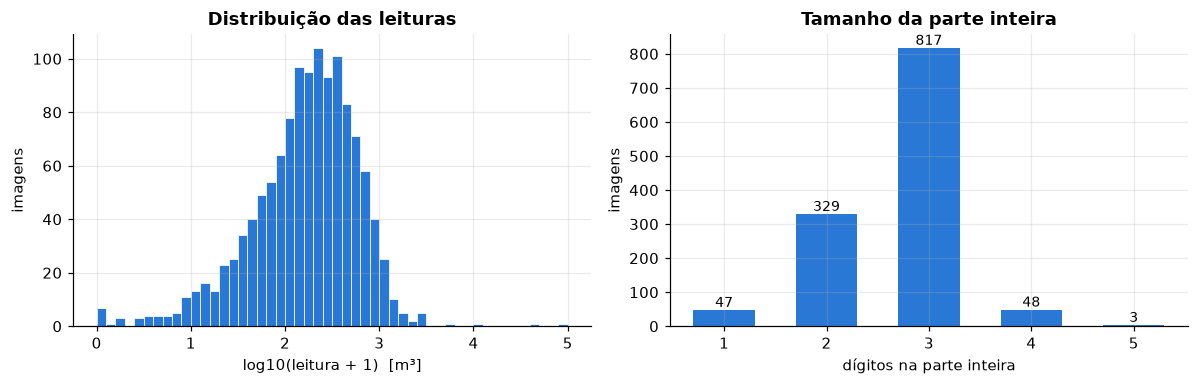

In [8]:
desc = meta.value.describe(percentiles=[.05, .25, .5, .75, .95, .99])
display(desc.to_frame('value').T.round(3))
print('value == 0:', int((meta.value == 0).sum()), '| value >= 10000:', int((meta.value >= 1e4).sum()))
print('Partes inteiras com 1–3 dígitos:', f'{(meta.int_str.str.len() <= 3).mean():.1%}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(np.log10(meta.value + 1), bins=50, color=COLORS['smallcnn'], edgecolor='white', linewidth=0.5)
axes[0].set_xlabel('log10(leitura + 1)  [m³]'); axes[0].set_ylabel('imagens'); axes[0].set_title('Distribuição das leituras')
ld = meta.int_str.str.len().value_counts().sort_index()
axes[1].bar(ld.index.astype(str), ld.values, color=COLORS['smallcnn'], width=0.6)
for x, v in zip(ld.index.astype(str), ld.values):
    axes[1].text(x, v, str(v), ha='center', va='bottom', fontsize=9)
axes[1].set_xlabel('dígitos na parte inteira'); axes[1].set_ylabel('imagens'); axes[1].set_title('Tamanho da parte inteira')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_readings.png', bbox_inches='tight'); plt.show()

Frequência de cada dígito (todas as posições):


C:\Users\Helder\AppData\Local\Temp\ipykernel_31300\1672046207.py:13: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  total = pos_counts.sum(1)


dígito,0,1,2,3,4,5,6,7,8,9
fração,0.357,0.101,0.078,0.078,0.07,0.068,0.064,0.062,0.062,0.059


C:\Users\Helder\AppData\Local\Temp\ipykernel_31300\1672046207.py:18: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  sns.heatmap(pos_counts / pos_counts.sum(0), annot=pos_counts, fmt='d', cmap='Blues', cbar_kws={'label': 'fração na posição'},


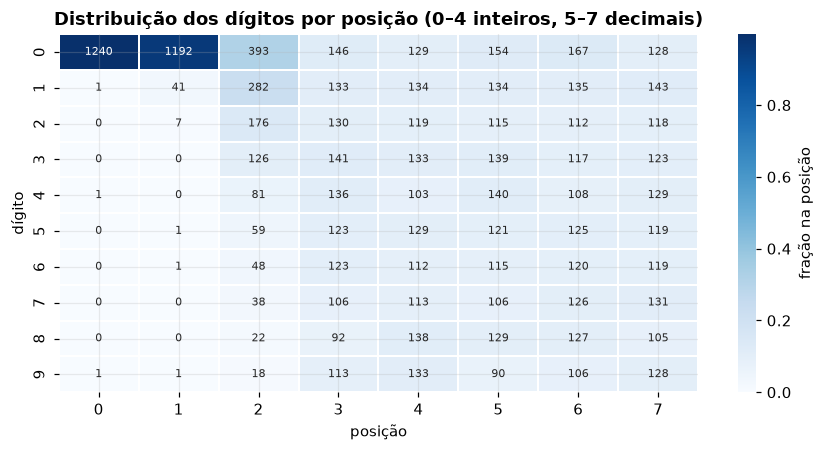

In [9]:
def label8(int_str, dec_str):
    # 5 dígitos inteiros (zeros à esquerda) + 3 decimais (zeros à direita perdidos pelo float)
    if len(int_str) > 5 or len(dec_str) > 3:
        return None
    return int_str.zfill(5) + dec_str.ljust(3, '0')


meta['label8'] = [label8(i, d) for i, d in zip(meta.int_str, meta.dec_str)]
valid = meta[meta.label8.notna()]
pos_counts = pd.DataFrame([[s[p] for p in range(8)] for s in valid.label8]).apply(lambda c: c.value_counts()).fillna(0).astype(int)
pos_counts = pos_counts.reindex([str(d) for d in range(10)]).fillna(0).astype(int)
pos_counts.index.name, pos_counts.columns.name = 'dígito', 'posição'
total = pos_counts.sum(1)
print('Frequência de cada dígito (todas as posições):')
display((total / total.sum()).rename('fração').to_frame().T.round(3))

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(pos_counts / pos_counts.sum(0), annot=pos_counts, fmt='d', cmap='Blues', cbar_kws={'label': 'fração na posição'},
            linewidths=1, linecolor='white', annot_kws={'fontsize': 7}, ax=ax)
ax.set_title('Distribuição dos dígitos por posição (0–4 inteiros, 5–7 decimais)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_digit_distribution.png', bbox_inches='tight'); plt.show()

## Parte 3 — Construção do dataset de dígitos

1. **Rótulo de 8 dígitos** a partir do nome do arquivo (`label8`); imagens fora do formato 5+3 são descartadas.
2. **Retificação**: retângulo de área mínima (`cv2.minAreaRect`) do polígono anotado → homografia para uma faixa
   de **384×64 px**, com o lado maior do retângulo mapeado na horizontal.
3. **Orientação**:
   * *vertical* — quando o eixo maior do visor está mais próximo da vertical, a faixa é girada 90°;
   * *de cabeça para baixo* — os 3 dígitos decimais costumam ser vermelhos. Quando a evidência de vermelho é
     forte (≥ 2 % dos pixels em uma das extremidades e 5× mais que na outra), ela decide a orientação. Para as
     faixas sem vermelho confiável, um **classificador binário de orientação** (CNN pequena, treinada só com as
     faixas confiáveis do split de *treino*, usando as próprias faixas giradas 180° como exemplos negativos)
     decide se a faixa deve ser girada 180°. Nenhum rótulo de dígito é usado nessa etapa.
4. Faixa dividida em **8 recortes de 48×64 px** e divisão conforme o `splits.csv` oficial.

In [10]:
W_STRIP, H_STRIP, N_DIG = 384, 64, 8
W_DIG = W_STRIP // N_DIG

splits = pd.read_csv(ROOT / 'splits.csv')
discarded = meta[meta.label8.isna()]
data = meta[meta.label8.notna()].merge(splits, on='photo_name', how='left', validate='one_to_one')
print('Válidas:', len(data), '| descartadas:', len(discarded), discarded.photo_name.tolist())
print('Sem split:', int(data.split.isna().sum()), '| imagens do splits.csv sem dado:', len(set(splits.photo_name) - set(data.photo_name)))
print(data.split.value_counts().to_dict())


def rectify(img, loc):
    # faixa 384x64 na orientação "ingênua": esquerda = menor x (visor horizontal) ou topo (visor vertical)
    h, w = img.shape[:2]
    box = cv2.boxPoints(cv2.minAreaRect(polygon_px(loc, w, h)))
    a, b = box[1] - box[0], box[2] - box[1]
    if a[0] * b[1] - a[1] * b[0] < 0:          # ordem horária (y para baixo), como TL, TR, BR, BL
        box = box[::-1]
    if np.linalg.norm(box[1] - box[0]) < np.linalg.norm(box[2] - box[1]):
        box = np.roll(box, -1, axis=0)           # lado maior vira a aresta superior
    axis = box[1] - box[0]
    vertical = abs(axis[1]) > abs(axis[0])
    if (not vertical and axis[0] < 0) or (vertical and axis[1] < 0):
        box = np.roll(box, 2, axis=0)
    dst = np.float32([[0, 0], [W_STRIP, 0], [W_STRIP, H_STRIP], [0, H_STRIP]])
    M = cv2.getPerspectiveTransform(box.astype(np.float32), dst)
    strip = cv2.warpPerspective(img, M, (W_STRIP, H_STRIP), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    return strip, vertical


def red_fraction(strip):
    hsv = cv2.cvtColor(strip, cv2.COLOR_BGR2HSV)
    red = ((hsv[..., 0] < 10) | (hsv[..., 0] > 165)) & (hsv[..., 1] > 90) & (hsv[..., 2] > 60)
    k = W_STRIP * 3 // 8
    return red[:, :k].mean(), red[:, -k:].mean()


strips, rows = {}, []
for r in data.itertuples():
    strip, vertical = rectify(cv2.imread(str(DATA_DIR / 'images' / r.photo_name)), r.location)
    left, right = red_fraction(strip)
    strips[r.photo_name] = strip
    rows.append((r.photo_name, vertical, left, right))
orient = pd.DataFrame(rows, columns=['photo_name', 'vertical', 'red_left', 'red_right']).merge(data[['photo_name', 'split']])
orient['red_confident'] = (((orient.red_right >= .02) & (orient.red_right > 5 * orient.red_left)) |
                           ((orient.red_left >= .02) & (orient.red_left > 5 * orient.red_right)))
orient['red_says_flip'] = orient.red_left > orient.red_right
print('Faixas verticais:', int(orient.vertical.sum()))
print('Faixas com evidência de vermelho confiável:', int(orient.red_confident.sum()), 'de', len(orient))

Válidas: 1243 | descartadas: 1 ['id_664_value_45_2676.jpg']
Sem split: 0 | imagens do splits.csv sem dado: 0
{'train': 870, 'test': 187, 'val': 186}


Faixas verticais: 105
Faixas com evidência de vermelho confiável: 880 de 1243


In [11]:
# Classificador binário de orientação (0 = em pé, 1 = de cabeça para baixo), treinado só com o split de treino
def to_small(s):
    return cv2.resize(s, (192, 32), interpolation=cv2.INTER_AREA)


Xo = torch.tensor(np.stack([to_small(strips[f]) for f in orient.photo_name])).permute(0, 3, 1, 2).float() / 255
tr_idx = np.where(orient.red_confident & (orient.split == 'train'))[0]
Xo_tr = Xo[tr_idx].clone()
flip_tr = torch.tensor(orient.red_says_flip.values[tr_idx])
Xo_tr[flip_tr] = Xo_tr[flip_tr].flip(2, 3)        # todas em pé


def orient_net():
    blk = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(blk(3, 16), blk(16, 32), blk(32, 64), blk(64, 64), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 1))


set_seed()
onet = orient_net().to(DEVICE)
opt = torch.optim.AdamW(onet.parameters(), 1e-3)
for ep in range(15):
    perm = torch.randperm(len(Xo_tr))
    for i in range(0, len(perm), 64):
        xb = Xo_tr[perm[i:i + 64]]
        yb = torch.rand(len(xb)) < .5
        xb = torch.where(yb[:, None, None, None], xb.flip(2, 3), xb) * (0.7 + 0.6 * torch.rand(len(xb), 1, 1, 1))
        loss = F.binary_cross_entropy_with_logits(onet(xb.to(DEVICE)).squeeze(1), yb.float().to(DEVICE))
        opt.zero_grad(); loss.backward(); opt.step()
onet.eval()
with torch.no_grad():
    orient['p_flip'] = torch.cat([torch.sigmoid(onet(Xo[i:i + 256].to(DEVICE))).squeeze(1).cpu()
                                  for i in range(0, len(Xo), 256)]).numpy()

agree = orient[orient.red_confident].assign(ok=lambda d: (d.p_flip > .5) == d.red_says_flip).groupby('split').ok.agg(['mean', 'size'])
print('Concordância classificador × vermelho confiável:'); display(agree.round(3))

orient['flip180'] = np.where(orient.red_confident, orient.red_says_flip, orient.p_flip > .5)
orient['orient_method'] = np.where(orient.red_confident, 'vermelho', 'classificador')
for f, fl in zip(orient.photo_name, orient.flip180):
    if fl:
        strips[f] = cv2.rotate(strips[f], cv2.ROTATE_180)

orient['correction'] = np.select([orient.vertical, orient.flip180], ['vertical (90°)', 'cabeça para baixo (180°)'], 'nenhuma')
summary = pd.crosstab(orient.correction, orient.orient_method, margins=True, margins_name='total')
display(summary)
N_CORRECTED = int((orient.correction != 'nenhuma').sum())
print(f'Faixas corrigidas: {N_CORRECTED} = {int(orient.vertical.sum())} verticais + '
      f'{int((~orient.vertical & orient.flip180).sum())} horizontais de cabeça para baixo')
orient.to_csv(REPORT_DIR / 'strip_orientation.csv', index=False)

Concordância classificador × vermelho confiável:


,mean,size
split,,
test,0.986,139
train,0.987,614
val,1.000,127


orient_method,classificador,vermelho,total
correction,,,
cabeça para baixo (180°),2,13,15
nenhuma,323,800,1123
vertical (90°),38,67,105
total,363,880,1243


Faixas corrigidas: 120 = 105 verticais + 15 horizontais de cabeça para baixo


In [12]:
# Recortes 48x64 e índice
for s in ['train', 'val', 'test']:
    shutil.rmtree(DIGITS_DIR / s, ignore_errors=True)
idx_rows = []
for r in data.itertuples():
    strip = strips[r.photo_name]
    for p in range(N_DIG):
        d = int(r.label8[p])
        path = DIGITS_DIR / r.split / str(d) / f'{r.image_id}_{p}.png'
        path.parent.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(path), strip[:, p * W_DIG:(p + 1) * W_DIG])
        idx_rows.append((r.image_id, r.photo_name, p, d, r.split, path.relative_to(ROOT).as_posix()))
index = pd.DataFrame(idx_rows, columns=['image_id', 'photo_name', 'position', 'digit', 'split', 'crop_path'])
index.to_csv(DIGITS_DIR / 'index.csv', index=False)

# Verificações obrigatórias
n_files = sum(1 for _ in DIGITS_DIR.rglob('*.png'))
img_split = index.groupby('photo_name').split.nunique()
checks = {'imagens válidas': (data.photo_name.nunique(), 1243), 'descartadas': (len(discarded), 1),
          'recortes no índice': (len(index), 9944), 'arquivos .png': (n_files, 9944),
          'imagens em >1 split': (int((img_split > 1).sum()), 0),
          'split != splits.csv': (int((index.drop_duplicates('photo_name').set_index('photo_name').split
                                      != splits.set_index('photo_name').split.reindex(index.drop_duplicates('photo_name').photo_name)).sum()), 0)}
display(pd.DataFrame(checks, index=['obtido', 'esperado']).T)
assert all(a == b for a, b in checks.values())
print(index.groupby('split').agg(imagens=('photo_name', 'nunique'), recortes=('crop_path', 'size')))

,obtido,esperado
imagens válidas,1243,1243
descartadas,1,1
recortes no índice,9944,9944
arquivos .png,9944,9944
imagens em >1 split,0,0
split != splits.csv,0,0


       imagens  recortes
split                   
test       187      1496
train      870      6960
val        186      1488


In [13]:
# Exemplos de faixas corrigidas (saída limpa antes do commit)
fig, axes = plt.subplots(6, 2, figsize=(12, 6))
ex = pd.concat([orient[orient.correction == c].sample(4, random_state=SEED) for c in ['vertical (90°)', 'cabeça para baixo (180°)']] +
               [orient[orient.correction == 'nenhuma'].sample(4, random_state=SEED)])
for ax, r in zip(axes.ravel(), ex.itertuples()):
    s = strips[r.photo_name].copy()
    for p in range(1, N_DIG):
        s[:, p * W_DIG] = (0, 255, 255)
    ax.imshow(cv2.cvtColor(s, cv2.COLOR_BGR2RGB)); ax.set_title(f'{r.correction} — {data.set_index("photo_name").label8[r.photo_name]}', fontsize=8)
    ax.axis('off')
plt.tight_layout(); plt.show()

## Parte 4 — Treinamento dos quatro modelos

| Modelo | Pesos | Entrada | Batch (CUDA) | Batch (MPS/CPU) | LR cabeça | LR backbone | Épocas |
|---|---|---|---|---|---|---|---|
| `smallcnn` | do zero | 64×48 | 256 | 128 | 1e-3 | — | 10 |
| `alexnet` | IMAGENET1K_V1 | 128×128 | 128 | 64 | 1e-3 | 1e-4 | 8 |
| `vgg16_bn` | IMAGENET1K_V1 | 128×128 | 32 | 16 | 1e-3 | 1e-5 | 8 |
| `resnet18` | IMAGENET1K_V1 | 128×128 | 128 | 64 | 1e-3 | 1e-4 | 8 |

Comum a todos: `AdamW` (weight decay 0,01) + `OneCycleLR` (por *batch*, `max_lr` = LR de cada grupo),
`CrossEntropyLoss(label_smoothing=0.1)`, 1ª época com backbone congelado (pré-treinados), *early stopping* pelo
F1-macro da validação com paciência 3, `seed=42`, *augmentation* `RandomAffine(degrees=5, translate=(0.05, 0.05),
scale=(0.95, 1.05))` + `ColorJitter(brightness=0.3, contrast=0.3)` sem flip, normalização ImageNet.

Detalhes de implementação (iguais para os quatro): a *augmentation* é aplicada no recorte original 64×48; o
redimensionamento para 128×128 (bilinear) e a normalização ocorrem na GPU. A **cabeça** é a última camada linear
(substituída por `Linear(·, 10)`); todo o resto é o **backbone**. A coluna `seconds` do histórico é o tempo de
treino da época, sem a validação.

In [14]:
PROTOCOL = {
    'smallcnn': dict(weights=None, size=(64, 48), batch=(256, 128), lr_head=1e-3, lr_backbone=None, epochs=10),
    'alexnet': dict(weights='IMAGENET1K_V1', size=(128, 128), batch=(128, 64), lr_head=1e-3, lr_backbone=1e-4, epochs=8),
    'vgg16_bn': dict(weights='IMAGENET1K_V1', size=(128, 128), batch=(32, 16), lr_head=1e-3, lr_backbone=1e-5, epochs=8),
    'resnet18': dict(weights='IMAGENET1K_V1', size=(128, 128), batch=(128, 64), lr_head=1e-3, lr_backbone=1e-4, epochs=8),
}
COMMON = dict(weight_decay=0.01, label_smoothing=0.1, patience=3, freeze_epochs=1)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


def load_crops(df):
    x = np.stack([cv2.cvtColor(cv2.imread(str(ROOT / p)), cv2.COLOR_BGR2RGB) for p in df.crop_path])
    return torch.from_numpy(x).permute(0, 3, 1, 2).contiguous()  # uint8 N x 3 x 64 x 48


index = pd.read_csv(DIGITS_DIR / 'index.csv')
parts = {s: index[index.split == s].reset_index(drop=True) for s in ['train', 'val', 'test']}
X = {s: load_crops(df) for s, df in parts.items()}
Y = {s: torch.tensor(df.digit.values) for s, df in parts.items()}
print({s: tuple(x.shape) for s, x in X.items()})

AUGMENT = v2.Compose([v2.RandomAffine(degrees=5, translate=(0.05, 0.05), scale=(0.95, 1.05)),
                      v2.ColorJitter(brightness=0.3, contrast=0.3)])


class DigitDataset(Dataset):
    def __init__(self, x, y, transform=None):
        self.x, self.y, self.transform = x, y, transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.x[i]
        return (self.transform(x) if self.transform else x), self.y[i]


def prep(x, size):
    x = x.to(DEVICE, non_blocking=True).float() / 255
    if tuple(x.shape[-2:]) != tuple(size):
        x = F.interpolate(x, size=size, mode='bilinear', align_corners=False)
    return (x - MEAN) / STD

{'train': (6960, 3, 64, 48), 'val': (1488, 3, 64, 48), 'test': (1496, 3, 64, 48)}


In [15]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        blk = lambda i, o: [nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True)]
        self.features = nn.Sequential(*blk(3, 32), *blk(32, 32), nn.MaxPool2d(2),     # 32x24
                                      *blk(32, 64), *blk(64, 64), nn.MaxPool2d(2),    # 16x12
                                      *blk(64, 128), nn.MaxPool2d(2))                 # 8x6
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128 * 8 * 6, 128),
                                        nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


def build_model(name):
    # retorna (modelo, parâmetros da cabeça, parâmetros do backbone)
    if name == 'smallcnn':
        m = SmallCNN()
        return m, list(m.parameters()), []
    if name == 'alexnet':
        m = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, 10); head = m.classifier[6]
    elif name == 'vgg16_bn':
        m = models.vgg16_bn(weights=models.VGG16_BN_Weights.IMAGENET1K_V1)
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, 10); head = m.classifier[6]
    elif name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, 10); head = m.fc
    head_ids = {id(p) for p in head.parameters()}
    return m, list(head.parameters()), [p for p in m.parameters() if id(p) not in head_ids]


def count(params):
    return sum(p.numel() for p in params)


rows = []
for name in MODELS:
    m, head, backbone = build_model(name)
    if name in ('alexnet', 'vgg16_bn', 'smallcnn'):
        conv, fc = count(m.features.parameters()), count(m.classifier.parameters())
    else:
        fc = count(m.fc.parameters()); conv = count(m.parameters()) - fc
    rows.append(dict(model=name, params_M=count(m.parameters()) / 1e6, conv_M=conv / 1e6, fc_M=fc / 1e6,
                     fc_frac=fc / count(m.parameters()), head_params=count(head)))
params_df = pd.DataFrame(rows).set_index('model')
display(params_df.round(4))

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to C:\Users\Helder/.cache\torch\hub\checkpoints\alexnet-owt-7be5be79.pth


  0%|          | 0.00/233M [00:00<?, ?B/s]

  0%|          | 1.00M/233M [00:00<00:25, 9.48MB/s]

  2%|▏         | 5.25M/233M [00:00<00:08, 27.7MB/s]

  5%|▌         | 11.9M/233M [00:00<00:05, 44.0MB/s]

...

 63%|██████▎   | 28.2M/44.7M [00:00<00:00, 61.2MB/s]

 77%|███████▋  | 34.4M/44.7M [00:00<00:00, 62.2MB/s]

 91%|█████████ | 40.5M/44.7M [00:00<00:00, 62.8MB/s]

100%|██████████| 44.7M/44.7M [00:00<00:00, 58.9MB/s]

,params_M,conv_M,fc_M,fc_frac,head_params
model,,,,,
smallcnn,0.9276,0.1397,0.7879,0.8493,927594
alexnet,57.0448,2.4697,54.5751,0.9567,40970
vgg16_bn,134.3100,14.7231,119.5868,0.8904,40970
resnet18,11.1816,11.1765,0.0051,0.0005,5130


In [16]:
@torch.no_grad()
def predict(model, x, size, bs=512):
    model.eval()
    return torch.cat([model(prep(x[i:i + bs], size)).float().cpu() for i in range(0, len(x), bs)])


def sync():
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    elif DEVICE == 'mps':
        torch.mps.synchronize()


def train_model(name):
    cfg = PROTOCOL[name]
    ckpt, hist_path = CKPT_DIR / f'{name}.pt', ROOT / f'history_{name}.csv'
    if not FORCE_TRAIN and ckpt.exists() and hist_path.exists():
        print(f'{name}: reaproveitando {ckpt.name}')
        return pd.read_csv(hist_path)
    set_seed()
    model, head, backbone = build_model(name)
    model.to(DEVICE)
    bs = cfg['batch'][0 if DEVICE == 'cuda' else 1]
    loader = DataLoader(DigitDataset(X['train'], Y['train'], AUGMENT), batch_size=bs, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED), num_workers=0)
    groups = [{'params': head, 'lr': cfg['lr_head']}]
    if backbone:
        groups.append({'params': backbone, 'lr': cfg['lr_backbone']})
    opt = torch.optim.AdamW(groups, weight_decay=COMMON['weight_decay'])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g['lr'] for g in groups], epochs=cfg['epochs'],
                                                steps_per_epoch=len(loader))
    crit = nn.CrossEntropyLoss(label_smoothing=COMMON['label_smoothing'])
    hist, best_f1, wait = [], -1.0, 0
    for epoch in range(1, cfg['epochs'] + 1):
        frozen = bool(backbone) and epoch <= COMMON['freeze_epochs']
        for p in backbone:
            p.requires_grad_(not frozen)
        model.train()
        sync(); t0 = time.perf_counter()
        loss_sum, correct, n = 0.0, 0, 0
        for xb, yb in loader:
            xb, yb = prep(xb, cfg['size']), yb.to(DEVICE)
            out = model(xb)
            loss = crit(out, yb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            loss_sum += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
        sync(); seconds = time.perf_counter() - t0
        logits = predict(model, X['val'], cfg['size'])
        val_loss = crit(logits, Y['val']).item()
        pred = logits.argmax(1).numpy()
        val_acc = accuracy_score(Y['val'], pred)
        val_f1 = f1_score(Y['val'], pred, average='macro', labels=list(range(10)))
        hist.append(dict(epoch=epoch, train_loss=loss_sum / n, train_acc=correct / n, val_loss=val_loss,
                         val_acc=val_acc, val_f1=val_f1, seconds=seconds))
        flag = ''
        if val_f1 > best_f1:
            best_f1, wait, flag = val_f1, 0, ' *'
            torch.save(model.state_dict(), ckpt)
        else:
            wait += 1
        print(f'{name} ep{epoch:2d}{" (backbone congelado)" if frozen else ""}: train_loss={loss_sum / n:.4f} '
              f'train_acc={correct / n:.4f} val_loss={val_loss:.4f} val_acc={val_acc:.4f} val_f1={val_f1:.4f} '
              f'{seconds:.1f}s{flag}')
        if wait >= COMMON['patience']:
            print(f'{name}: early stopping na época {epoch}')
            break
    hist = pd.DataFrame(hist)
    hist.to_csv(hist_path, index=False)
    return hist


t_start = time.perf_counter()
histories = {name: train_model(name) for name in MODELS}
print(f'Tempo total de treino: {(time.perf_counter() - t_start) / 60:.1f} min')

smallcnn ep 1: train_loss=2.1424 train_acc=0.3339 val_loss=2.0801 val_acc=0.3710 val_f1=0.0541 7.1s *


smallcnn ep 2: train_loss=2.0206 train_acc=0.3596 val_loss=1.9029 val_acc=0.3750 val_f1=0.0826 5.2s *


smallcnn ep 3: train_loss=1.8310 train_acc=0.4188 val_loss=1.6135 val_acc=0.5215 val_f1=0.3219 5.1s *


smallcnn ep 4: train_loss=1.5821 train_acc=0.5443 val_loss=1.4454 val_acc=0.6337 val_f1=0.4969 4.9s *


smallcnn ep 5: train_loss=1.4226 train_acc=0.6214 val_loss=1.2481 val_acc=0.7325 val_f1=0.6518 4.9s *


...

resnet18 ep 5: train_loss=0.6295 train_acc=0.9621 val_loss=0.7006 val_acc=0.9415 val_f1=0.9329 6.9s *


resnet18 ep 6: train_loss=0.5959 train_acc=0.9727 val_loss=0.6860 val_acc=0.9442 val_f1=0.9367 6.9s *


resnet18 ep 7: train_loss=0.5824 train_acc=0.9783 val_loss=0.6804 val_acc=0.9462 val_f1=0.9385 6.9s *


resnet18 ep 8: train_loss=0.5771 train_acc=0.9799 val_loss=0.6840 val_acc=0.9449 val_f1=0.9380 7.0s


Tempo total de treino: 10.5 min


## Parte 5 — Avaliação no conjunto de teste

Todas as métricas abaixo usam o **melhor checkpoint** (maior F1-macro de validação) avaliado no **teste**.
`ms_per_image`: batch 1, mediana de 200 execuções após 20 de *warm-up*, no mesmo dispositivo do treino (entrada já
pré-processada). Como referência adicional para a Questão 5.4, medimos também a latência em CPU.

In [17]:
def latency_ms(model, size, device, warmup=20, runs=200):
    model = model.to(device).eval()
    x = torch.randn(1, 3, *size, device=device)
    sync_fn = torch.cuda.synchronize if device == 'cuda' else (lambda: None)
    times = []
    with torch.no_grad():
        for i in range(warmup + runs):
            sync_fn(); t0 = time.perf_counter()
            model(x)
            sync_fn()
            if i >= warmup:
                times.append(time.perf_counter() - t0)
    return float(np.median(times) * 1000)


test_df = parts['test'].copy()
results, preds, probs, cpu_lat = [], {}, {}, {}
for name in MODELS:
    cfg = PROTOCOL[name]
    model, _, _ = build_model(name)
    model.load_state_dict(torch.load(CKPT_DIR / f'{name}.pt', map_location='cpu'))
    model.to(DEVICE)
    logits = predict(model, X['test'], cfg['size'])
    p = logits.softmax(1).numpy(); y_pred = p.argmax(1)
    probs[name], preds[name] = p, y_pred
    test_df[f'pred_{name}'] = y_pred
    ok = (y_pred == test_df.digit.values)
    hist = histories[name]
    results.append(dict(
        model=name,
        acc_digit=ok.mean(),
        f1_macro=f1_score(test_df.digit, y_pred, average='macro', labels=list(range(10))),
        acc_reading=pd.Series(ok).groupby(test_df.image_id.values).all().mean(),
        params_M=count(model.parameters()) / 1e6,
        s_per_epoch=hist.seconds.median(),
        ms_per_image=latency_ms(model, cfg['size'], DEVICE),
        ckpt_MB=(CKPT_DIR / f'{name}.pt').stat().st_size / 2**20,
        best_epoch=int(hist.loc[hist.val_f1.idxmax(), 'epoch'])))
    torch.set_num_threads(os.cpu_count())
    cpu_lat[name] = latency_ms(model.to('cpu'), cfg['size'], 'cpu')
    rep = classification_report(test_df.digit, y_pred, digits=4, labels=list(range(10)), zero_division=0)
    (REPORT_DIR / f'classification_report_{name}.txt').write_text(rep)
    print(f'===== {name} =====\n{rep}')

res = pd.DataFrame(results)
res = res.round({'acc_digit': 4, 'f1_macro': 4, 'acc_reading': 4, 'params_M': 3, 's_per_epoch': 2, 'ms_per_image': 3, 'ckpt_MB': 2})
res.to_csv(ROOT / 'results.csv', index=False)
display(res)
print('Latência em CPU, batch 1 (ms/imagem):', {k: round(v, 2) for k, v in cpu_lat.items()})
pd.Series(cpu_lat, name='cpu_ms_per_image').round(3).to_csv(REPORT_DIR / 'cpu_latency.csv')

===== smallcnn =====
              precision    recall  f1-score   support

           0     0.8495    0.9534    0.8984       515
           1     0.7692    0.8000    0.7843       150
           2     0.8527    0.8462    0.8494       130
           3     0.8384    0.7477    0.7905       111
           4     0.8462    0.6814    0.7549       113
           5     0.7188    0.7188    0.7188        96
           6     0.6900    0.6330    0.6603       109
           7     0.6632    0.8400    0.7412        75
           8     0.8250    0.5893    0.6875       112
           9     0.6944    0.5882    0.6369        85

    accuracy                         0.8008      1496
   macro avg     0.7747    0.7398    0.7522      1496
weighted avg     0.8006    0.8008    0.7965      1496



===== alexnet =====
              precision    recall  f1-score   support

           0     0.9705    0.9592    0.9648       515
           1     0.9504    0.8933    0.9210       150
           2     0.8913    0.9462    0.9179       130
           3     0.9406    0.8559    0.8962       111
           4     0.9252    0.8761    0.9000       113
           5     0.8571    0.9375    0.8955        96
           6     0.9596    0.8716    0.9135       109
           7     0.8519    0.9200    0.8846        75
           8     0.8197    0.8929    0.8547       112
           9     0.7849    0.8588    0.8202        85

    accuracy                         0.9171      1496
   macro avg     0.8951    0.9011    0.8968      1496
weighted avg     0.9201    0.9171    0.9177      1496



===== vgg16_bn =====
              precision    recall  f1-score   support

           0     0.9489    0.9728    0.9607       515
           1     0.9161    0.8733    0.8942       150
           2     0.9615    0.9615    0.9615       130
           3     0.9369    0.9369    0.9369       111
           4     0.8870    0.9027    0.8947       113
           5     0.9556    0.8958    0.9247        96
           6     0.9524    0.9174    0.9346       109
           7     0.9000    0.9600    0.9290        75
           8     0.9717    0.9196    0.9450       112
           9     0.8864    0.9176    0.9017        85

    accuracy                         0.9372      1496
   macro avg     0.9316    0.9258    0.9283      1496
weighted avg     0.9375    0.9372    0.9370      1496



===== resnet18 =====
              precision    recall  f1-score   support

           0     0.9675    0.9825    0.9750       515
           1     0.9510    0.9067    0.9283       150
           2     0.9615    0.9615    0.9615       130
           3     0.9821    0.9910    0.9865       111
           4     0.9640    0.9469    0.9554       113
           5     0.9479    0.9479    0.9479        96
           6     0.9717    0.9450    0.9581       109
           7     0.9221    0.9467    0.9342        75
           8     0.9558    0.9643    0.9600       112
           9     0.9294    0.9294    0.9294        85

    accuracy                         0.9599      1496
   macro avg     0.9553    0.9522    0.9536      1496
weighted avg     0.9599    0.9599    0.9598      1496



,model,acc_digit,f1_macro,acc_reading,params_M,s_per_epoch,ms_per_image,ckpt_MB,best_epoch
0,smallcnn,0.8008,0.7522,0.2941,0.928,5.03,0.982,3.55,10
1,alexnet,0.9171,0.8968,0.6257,57.045,5.48,1.347,217.61,6
2,vgg16_bn,0.9372,0.9283,0.7112,134.310,29.19,3.325,512.41,7
3,resnet18,0.9599,0.9536,0.8449,11.182,6.94,3.020,42.73,7


Latência em CPU, batch 1 (ms/imagem): {'smallcnn': 2.42, 'alexnet': 9.94, 'vgg16_bn': 40.51, 'resnet18': 9.36}


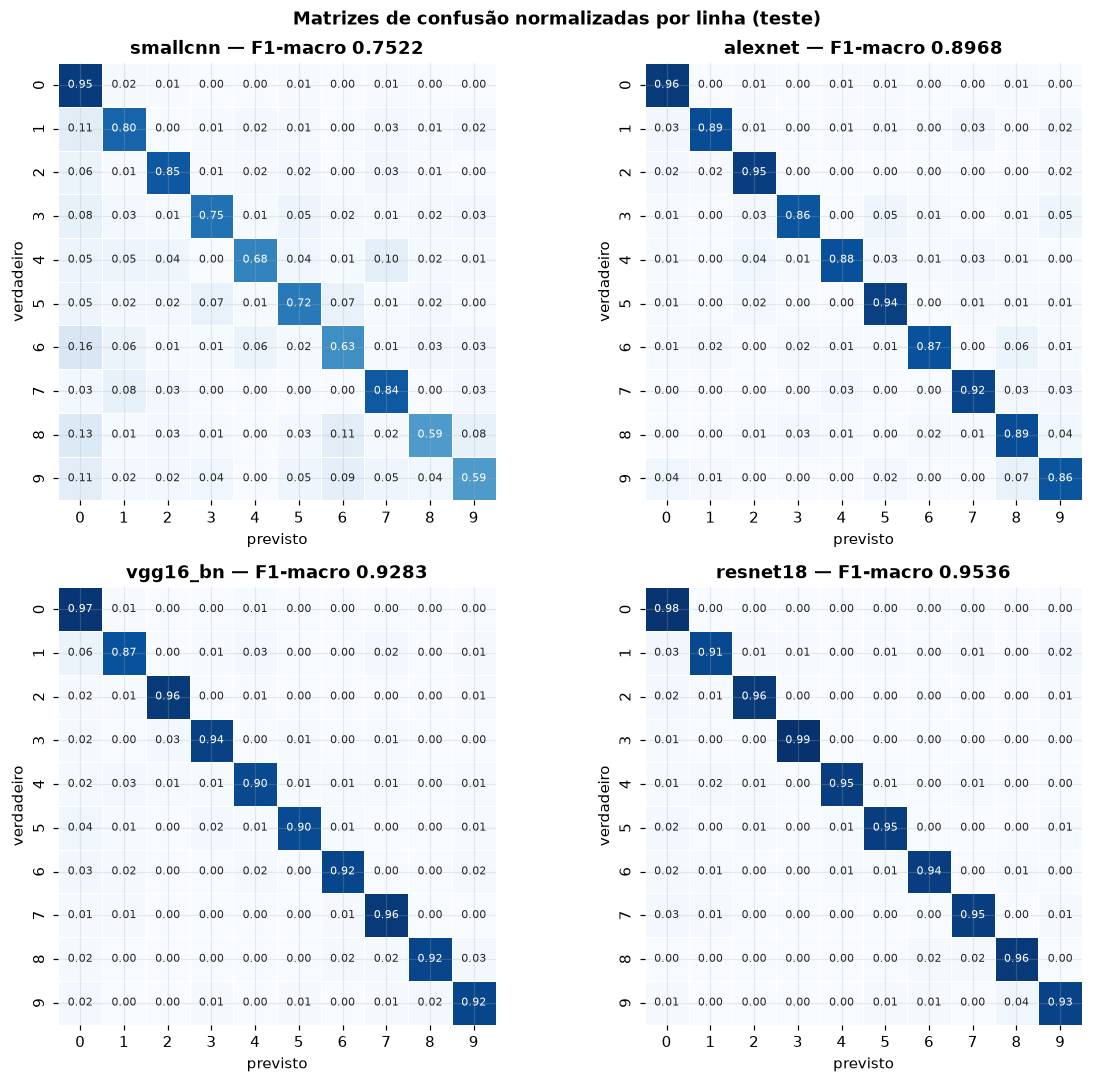

C:\Users\Helder\AppData\Local\Temp\ipykernel_31300\1142651669.py:22: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  top_pairs['total'] = top_pairs.sum(1)


,model,smallcnn,alexnet,vgg16_bn,resnet18,total
verdadeiro,previsto,,,,,
1,0,16.0,5.0,9.0,5.0,35.0
6,0,17.0,1.0,3.0,2.0,23.0
8,6,12.0,2.0,2.0,2.0,18.0
0,1,9.0,2.0,4.0,2.0,17.0
8,0,15.0,0.0,2.0,0.0,17.0
4,7,11.0,3.0,1.0,1.0,16.0
2,0,8.0,3.0,2.0,3.0,16.0
8,9,9.0,4.0,3.0,0.0,16.0
9,0,9.0,3.0,2.0,1.0,15.0


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
cms = {}
for ax, name in zip(axes.ravel(), MODELS):
    cm = confusion_matrix(test_df.digit, preds[name], labels=list(range(10)), normalize='true')
    cms[name] = confusion_matrix(test_df.digit, preds[name], labels=list(range(10)))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False, square=True,
                linewidths=0.5, linecolor='white', annot_kws={'fontsize': 7}, ax=ax)
    f1 = res.set_index('model').f1_macro[name]
    ax.set_title(f'{name} — F1-macro {f1:.4f}'); ax.set_xlabel('previsto'); ax.set_ylabel('verdadeiro')
fig.suptitle('Matrizes de confusão normalizadas por linha (teste)', fontweight='bold')
plt.tight_layout(); plt.savefig(FIG_DIR / 'confusion_matrices.png', bbox_inches='tight'); plt.show()

# pares mais confundidos (soma dos quatro modelos e por modelo)
pairs = []
for name, cm in cms.items():
    for t in range(10):
        for p in range(10):
            if t != p and cm[t, p]:
                pairs.append(dict(model=name, verdadeiro=t, previsto=p, n=int(cm[t, p])))
pairs = pd.DataFrame(pairs)
top_pairs = pairs.pivot_table(index=['verdadeiro', 'previsto'], columns='model', values='n', fill_value=0)[MODELS]
top_pairs['total'] = top_pairs.sum(1)
display(top_pairs.sort_values('total', ascending=False).head(12))

position,0,1,2,3,4,5,6,7
smallcnn,0.9626,0.9572,0.8396,0.7540,0.7647,0.7647,0.8449,0.5187
alexnet,0.9679,0.9679,0.9305,0.9412,0.8984,0.9251,0.9198,0.7861
vgg16_bn,0.9840,0.9679,0.9251,0.9358,0.9412,0.9465,0.9572,0.8396
resnet18,0.9893,0.9840,0.9465,0.9519,0.9465,0.9733,0.9733,0.9144


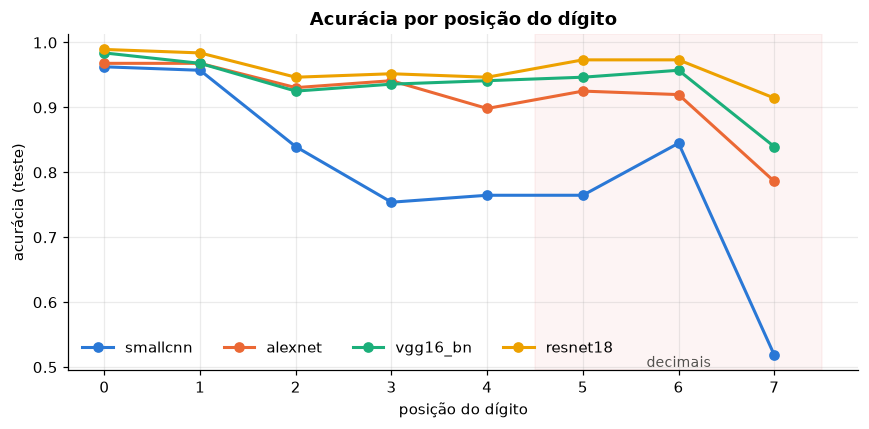

In [19]:
pos_acc = pd.DataFrame({name: test_df.assign(ok=preds[name] == test_df.digit).groupby('position').ok.mean() for name in MODELS})
display(pos_acc.round(4).T)
fig, ax = plt.subplots(figsize=(8, 4))
for name in MODELS:
    ax.plot(pos_acc.index, pos_acc[name], marker='o', markersize=6, linewidth=2, color=COLORS[name], label=name)
ax.axvspan(4.5, 7.5, color='#e34948', alpha=0.06)
ax.text(6, ax.get_ylim()[0], 'decimais', ha='center', va='bottom', fontsize=9, color='#52514e')
ax.set_xticks(range(8)); ax.set_xlabel('posição do dígito'); ax.set_ylabel('acurácia (teste)')
ax.set_title('Acurácia por posição do dígito'); ax.legend(frameon=False, ncol=4, loc='lower left')
plt.tight_layout(); plt.savefig(FIG_DIR / 'accuracy_by_position.png', bbox_inches='tight'); plt.show()

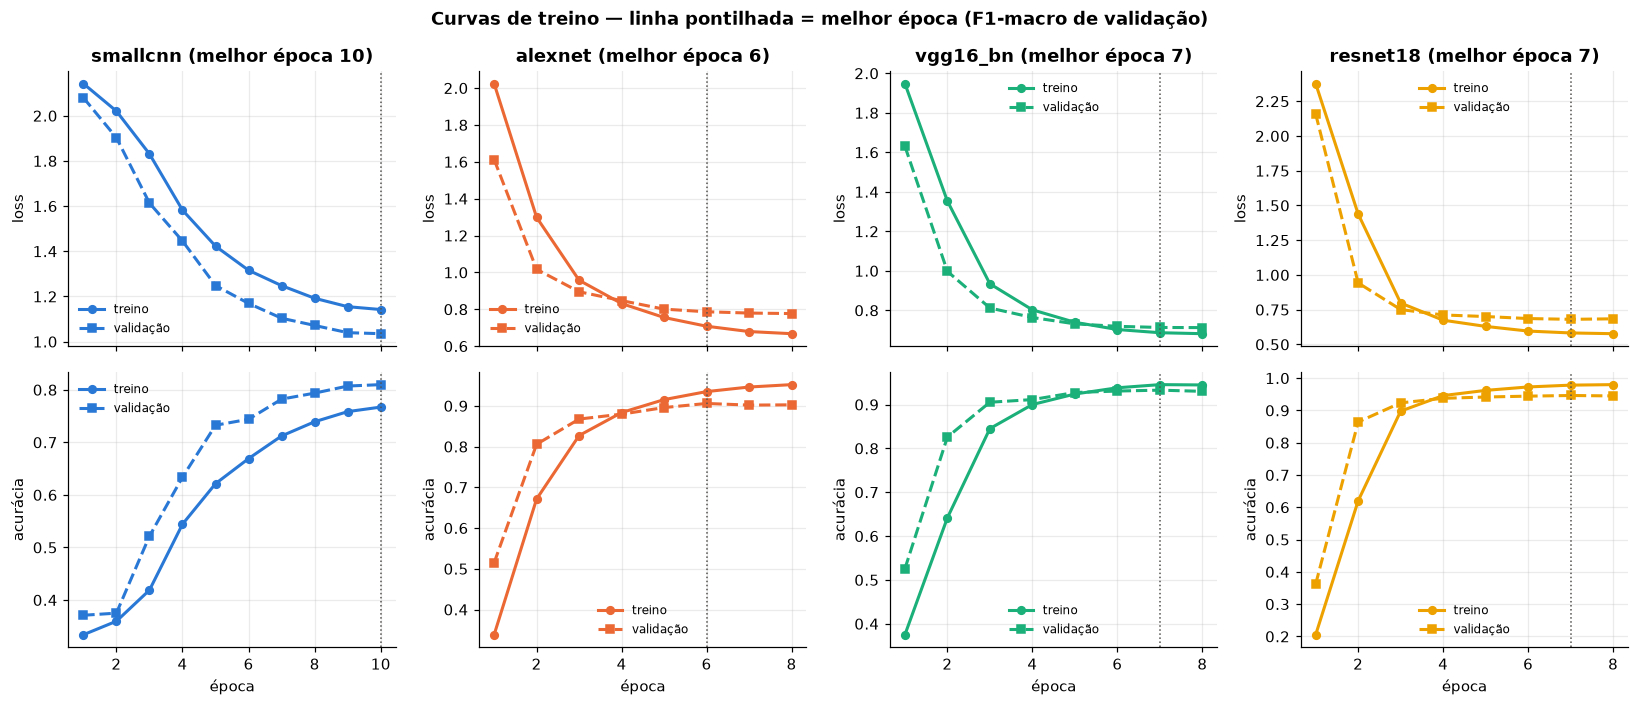

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharex='col')
for j, name in enumerate(MODELS):
    h = histories[name]
    best = int(h.loc[h.val_f1.idxmax(), 'epoch'])
    for i, (metric, label) in enumerate([('loss', 'loss'), ('acc', 'acurácia')]):
        ax = axes[i, j]
        ax.plot(h.epoch, h[f'train_{metric}'], marker='o', markersize=5, linewidth=2, color=COLORS[name], label='treino')
        ax.plot(h.epoch, h[f'val_{metric}'], marker='s', markersize=5, linewidth=2, color=COLORS[name], linestyle='--', label='validação')
        ax.axvline(best, color='#52514e', linewidth=1, linestyle=':')
        ax.set_ylabel(label)
        if i == 0:
            ax.set_title(f'{name} (melhor época {best})')
        if i == 1:
            ax.set_xlabel('época')
        ax.legend(frameon=False, fontsize=8)
fig.suptitle('Curvas de treino — linha pontilhada = melhor época (F1-macro de validação)', fontweight='bold')
plt.tight_layout(); plt.savefig(FIG_DIR / 'training_curves.png', bbox_inches='tight'); plt.show()

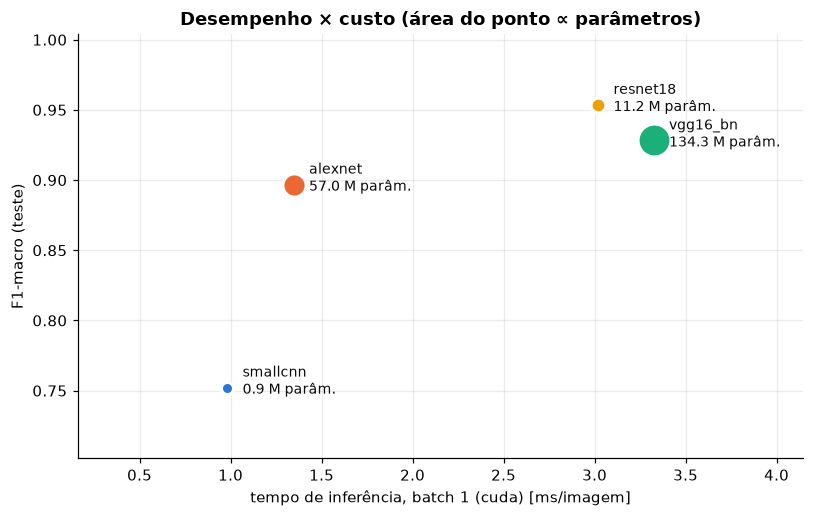

In [21]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
r = res.set_index('model')
for name in MODELS:
    ax.scatter(r.ms_per_image[name], r.f1_macro[name], s=60 + 3 * r.params_M[name], color=COLORS[name],
               edgecolor='white', linewidth=2, zorder=3)
    ax.annotate(f'{name}\n{r.params_M[name]:.1f} M parâm.', (r.ms_per_image[name], r.f1_macro[name]),
                textcoords='offset points', xytext=(10, -4), fontsize=9, color='#0b0b0b')
ax.set_xlabel(f'tempo de inferência, batch 1 ({DEVICE}) [ms/imagem]'); ax.set_ylabel('F1-macro (teste)')
ax.set_title('Desempenho × custo (área do ponto ∝ parâmetros)')
ax.margins(x=0.35, y=0.25)
plt.tight_layout(); plt.savefig(FIG_DIR / 'performance_vs_cost.png', bbox_inches='tight'); plt.show()

In [22]:
# Galeria: 16 erros mais confiantes de cada modelo (saída limpa antes do commit)
for name in MODELS:
    p = probs[name]; y_pred = preds[name]
    err = np.where(y_pred != test_df.digit.values)[0]
    err = err[np.argsort(-p[err, y_pred[err]])][:16]
    fig, axes = plt.subplots(2, 8, figsize=(13, 4))
    for ax, i in zip(axes.ravel(), err):
        ax.imshow(X['test'][i].permute(1, 2, 0).numpy())
        ax.set_title(f'v={test_df.digit[i]} p={y_pred[i]} ({p[i, y_pred[i]]:.2f})\npos {test_df.position[i]}', fontsize=8)
    for ax in axes.ravel():
        ax.axis('off')
    fig.suptitle(f'{name}: 16 erros mais confiantes', fontweight='bold'); plt.tight_layout(); plt.show()

### Análise de erros

Quantificação dos tipos de recorte errado (Questão 3.2) e de onde os modelos erram (Questões 5.2 e 5.3).
A orientação residual é estimada com o melhor modelo: para cada faixa, comparamos a log-verossimilhança do rótulo nos
8 recortes da faixa como está e da faixa girada 180°. Isso usa os rótulos e por isso **não** é usado no pipeline —
serve apenas para diagnóstico.

In [23]:
best_name = res.sort_values('f1_macro', ascending=False).model.iloc[0]
cfg = PROTOCOL[best_name]
best_model, _, _ = build_model(best_name)
best_model.load_state_dict(torch.load(CKPT_DIR / f'{best_name}.pt', map_location='cpu')); best_model.to(DEVICE)
print('Modelo usado no diagnóstico:', best_name)


def crops_of(strip):
    return [cv2.cvtColor(strip[:, p * W_DIG:(p + 1) * W_DIG], cv2.COLOR_BGR2RGB) for p in range(N_DIG)]


diag = []
lab = data.set_index('photo_name').label8
for f in orient.photo_name:
    s = strips[f]
    xs = torch.from_numpy(np.stack(crops_of(s) + crops_of(cv2.rotate(s, cv2.ROTATE_180)))).permute(0, 3, 1, 2)
    lp = predict(best_model, xs, cfg['size']).log_softmax(1).numpy()
    y = np.array([int(c) for c in lab[f]])
    cur, rot = lp[:8][np.arange(8), y], lp[8:][np.arange(8), y]
    diag.append(dict(photo_name=f, ll_cur=cur.sum(), ll_rot=rot.sum(), ok_cur=(lp[:8].argmax(1) == y).sum(),
                     ok_rot=(lp[8:].argmax(1) == y).sum()))
diag = pd.DataFrame(diag).merge(orient[['photo_name', 'split', 'vertical', 'flip180', 'orient_method']])
diag['wrong_orientation'] = (diag.ll_rot > diag.ll_cur) & (diag.ok_rot >= diag.ok_cur + 3)
print('Faixas provavelmente ainda de cabeça para baixo (por split):')
display(diag.groupby('split').wrong_orientation.agg(['sum', 'size']))
display(diag[diag.wrong_orientation].groupby(['vertical', 'orient_method']).size().rename('faixas').to_frame())

Modelo usado no diagnóstico: resnet18


Faixas provavelmente ainda de cabeça para baixo (por split):


,sum,size
split,,
test,2,187
train,8,870
val,3,186


,,faixas
vertical,orient_method,
False,classificador,3
True,classificador,10


In [24]:
# Tipos de erro no teste (melhor modelo)
t = test_df.assign(pred=preds[best_name], ok=lambda d: d.pred == d.digit)
per_img = t.groupby('photo_name').agg(n_err=('ok', lambda s: int((~s).sum())))
per_img = per_img.join(diag.set_index('photo_name')[['wrong_orientation', 'vertical']])
print('Imagens de teste por número de dígitos errados:', per_img.n_err.value_counts().sort_index().to_dict())

e = t[~t.ok].copy()
e['diff'] = (e.pred - e.digit) % 10
e['adjacent'] = e['diff'].isin([1, 9])                     # tambor em transição (d → d±1)
e['img_wrong_orient'] = e.photo_name.map(diag.set_index('photo_name').wrong_orientation)
e['img_many_errors'] = e.photo_name.map(per_img.n_err) >= 4
cat = np.select([e.img_wrong_orient, e.img_many_errors, e.adjacent],
                ['faixa de cabeça para baixo', 'faixa com ≥4 erros (recorte/desalinhamento)', 'dígito vizinho (tambor rolando)'],
                'outros (borrão, reflexo, confusão de forma)')
error_types = pd.Series(cat).value_counts().rename('erros').to_frame()
error_types['fração'] = (error_types.erros / len(e)).round(3)
display(error_types)
print('Erros por posição:', e.position.value_counts().sort_index().to_dict())
error_types.to_csv(REPORT_DIR / 'error_types_test.csv')

Imagens de teste por número de dígitos errados: {0: 158, 1: 18, 2: 3, 3: 3, 4: 1, 5: 2, 6: 1, 7: 1}


,erros,fração
"outros (borrão, reflexo, confusão de forma)",24,0.400
faixa com ≥4 erros (recorte/desalinhamento),14,0.233
faixa de cabeça para baixo,13,0.217
dígito vizinho (tambor rolando),9,0.150


Erros por posição: {0: 2, 1: 3, 2: 10, 3: 9, 4: 10, 5: 5, 6: 5, 7: 16}


In [25]:
# Imagens de teste com mais erros (saída limpa antes do commit)
worst = per_img.sort_values('n_err', ascending=False).head(8)
fig, axes = plt.subplots(4, 2, figsize=(12, 4.5))
for ax, (f, r) in zip(axes.ravel(), worst.iterrows()):
    ax.imshow(cv2.cvtColor(strips[f], cv2.COLOR_BGR2RGB))
    pr = ''.join(map(str, t[t.photo_name == f].sort_values('position').pred))
    ax.set_title(f'rótulo {lab[f]}  previsto {pr}  ({r.n_err} erros)', fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [26]:
# Resumo para o README
print(res.to_markdown(index=False))
print()
print(pd.Series(cpu_lat).round(2).to_frame('cpu_ms_per_image').T.to_markdown())

| model    |   acc_digit |   f1_macro |   acc_reading |   params_M |   s_per_epoch |   ms_per_image |   ckpt_MB |   best_epoch |
|:---------|------------:|-----------:|--------------:|-----------:|--------------:|---------------:|----------:|-------------:|
| smallcnn |      0.8008 |     0.7522 |        0.2941 |      0.928 |          5.03 |          0.982 |      3.55 |           10 |
| alexnet  |      0.9171 |     0.8968 |        0.6257 |     57.045 |          5.48 |          1.347 |    217.61 |            6 |
| vgg16_bn |      0.9372 |     0.9283 |        0.7112 |    134.31  |         29.19 |          3.325 |    512.41 |            7 |
| resnet18 |      0.9599 |     0.9536 |        0.8449 |     11.182 |          6.94 |          3.02  |     42.73 |            7 |

|                  |   smallcnn |   alexnet |   vgg16_bn |   resnet18 |
|:-----------------|-----------:|----------:|-----------:|-----------:|
| cpu_ms_per_image |       2.42 |      9.94 |      40.51 |       9.36 |
